# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** [Input Nama]
- **Email:** [Input Email]
- **ID Dicoding:** [Input Username]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

---

**Pertanyaan Bisnis yang Dirumuskan:**
- **Pertanyaan 1:** Bagaimana pengaruh kondisi cuaca (*weathersit*) dan musim (*season*) terhadap rata-rata jumlah penyewaan sepeda harian (*cnt*) selama periode tahun 2011 hingga 2012?
- **Pertanyaan 2:** Bagaimana pola fluktuasi jumlah penyewaan sepeda per jam (*hr*) pada hari kerja (*workingday*) dibandingkan dengan hari libur/akhir pekan, dan pada jam berapa saja terjadi jam sibuk (*peak hours*) penyewaan sepeda selama tahun 2011 hingga 2012?

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 11
plt.rcParams['figure.figsize'] = (10, 6)

## Data Wrangling

### Gathering Data

#### Load df day.csv dan hour.csv

In [2]:
import os

# Mendukung pembacaan dataset baik dari folder data (data_1.csv / day.csv) maupun Dataset
day_path = 'data/day.csv' if os.path.exists('data/day.csv') else ('Dataset/day.csv' if os.path.exists('Dataset/day.csv') else 'data/data_1.csv')
hour_path = 'data/hour.csv' if os.path.exists('data/hour.csv') else ('Dataset/hour.csv' if os.path.exists('Dataset/hour.csv') else 'data/data_2.csv')

day_df = pd.read_csv(day_path)
hour_df = pd.read_csv(hour_path)

print(f'Dataset day_df berhasil dimuat dari: {day_path}')
display(day_df.head())

print(f'\nDataset hour_df berhasil dimuat dari: {hour_path}')
display(hour_df.head())

Dataset day_df berhasil dimuat dari: data/day.csv


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600



Dataset hour_df berhasil dimuat dari: data/hour.csv


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- Dataset `day_df` terdiri dari 731 baris dan 16 kolom yang merekam data penyewaan sepeda harian.
- Dataset `hour_df` terdiri dari 17.379 baris dan 17 kolom yang merekam data penyewaan sepeda per jam dengan atribut tambahan `hr` (jam 0-23).
- Fitur-fitur mencakup informasi waktu (`dteday`, `season`, `yr`, `mnth`, `holiday`, `weekday`, `workingday`), parameter cuaca (`weathersit`, `temp`, `atemp`, `hum`, `windspeed`), dan jumlah rental (`casual`, `registered`, `cnt`).

### Assessing Data

#### Identifying Data Type, Missing Value, Duplicate, and Statistical Summary

In [3]:
print("="*40)
print("INFORMASI STRUKTUR DATA (day_df)")
print("="*40)
day_df.info()

print("\n" + "="*40)
print("INFORMASI STRUKTUR DATA (hour_df)")
print("="*40)
hour_df.info()

print("\n" + "="*40)
print("PENGECEKAN MISSING VALUES")
print("="*40)
print("Missing values day_df:\n", day_df.isna().sum())
print("\nMissing values hour_df:\n", hour_df.isna().sum())

print("\n" + "="*40)
print("PENGECEKAN DUPLIKASI DATA")
print("="*40)
print("Jumlah data terduplikasi day_df:", day_df.duplicated().sum())
print("Jumlah data terduplikasi hour_df:", hour_df.duplicated().sum())

print("\n" + "="*40)
print("RINGKASAN STATISTIK DESKRIPTIF (day_df)")
print("="*40)
display(day_df.describe())

print("\n" + "="*40)
print("RINGKASAN STATISTIK DESKRIPTIF (hour_df)")
print("="*40)
display(hour_df.describe())

INFORMASI STRUKTUR DATA (day_df)
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB

INFORMASI STRUKTUR DATA (hour_df)
<class 'pandas.DataFrame'>
RangeIndex: 1

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000



RINGKASAN STATISTIK DESKRIPTIF (hour_df)


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


**Steps to Take:**
1. **Konversi Tipe Data:** Mengubah tipe data kolom `dteday` dari `object` (string) menjadi tipe `datetime64[ns]` pada `day_df` dan `hour_df` agar mempermudah operasi time series.
2. **Penambahan Kolom Kategorikal Deskriptif:** Membuat kolom label pembantu (`season_label`, `weather_label`, `year_label`, `workingday_label`) untuk memudahkan pembacaan label dalam proses analisis dan visualisasi data, tanpa menghapus kolom numerik aslinya.
3. **Pemeriksaan Konsistensi:** Memastikan rentang data numerik (`temp`, `atemp`, `hum`, `windspeed`, `cnt`) berada pada batasan yang wajar dan konsisten.

**Insight:**
- Tidak ditemukan nilai yang hilang (*missing values*) pada kedua dataset (0 missing values).
- Tidak ditemukan baris data ganda (*duplicate rows*) pada kedua dataset (0 duplicated).
- Kolom `dteday` masih bertipe `object` dan harus dikonversi menjadi `datetime`.
- Variabel cuaca (`temp`, `atemp`, `hum`, `windspeed`) berada pada rentang normalisasi yang tepat.

### Cleaning Data

#### Fixing Data Types and Adding Readable Categorical Labels

In [4]:
# 1. Konversi tipe data dteday menjadi datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# 2. Kamus pemetaan label kategorikal
season_mapping = {
    1: 'Spring',
    2: 'Summer',
    3: 'Fall',
    4: 'Winter'
}

weather_mapping = {
    1: 'Clear/Partly Cloudy',
    2: 'Mist/Cloudy',
    3: 'Light Snow/Rain',
    4: 'Severe Weather'
}

year_mapping = {
    0: '2011',
    1: '2012'
}

workingday_mapping = {
    0: 'Weekend/Holiday',
    1: 'Working Day'
}

# 3. Menerapkan pemetaan pada day_df
day_df['season_label'] = day_df['season'].map(season_mapping)
day_df['weather_label'] = day_df['weathersit'].map(weather_mapping)
day_df['year_label'] = day_df['yr'].map(year_mapping)
day_df['workingday_label'] = day_df['workingday'].map(workingday_mapping)

# 4. Menerapkan pemetaan pada hour_df
hour_df['season_label'] = hour_df['season'].map(season_mapping)
hour_df['weather_label'] = hour_df['weathersit'].map(weather_mapping)
hour_df['year_label'] = hour_df['yr'].map(year_mapping)
hour_df['workingday_label'] = hour_df['workingday'].map(workingday_mapping)

# 5. Verifikasi tipe data setelah proses cleaning
print("Tipe data kolom tanggal dan label baru pada day_df:")
print(day_df[['dteday', 'season_label', 'weather_label', 'year_label', 'workingday_label']].dtypes)
print("\nTipe data kolom tanggal dan label baru pada hour_df:")
print(hour_df[['dteday', 'season_label', 'weather_label', 'year_label', 'workingday_label']].dtypes)

Tipe data kolom tanggal dan label baru pada day_df:
dteday              datetime64[us]
season_label                   str
weather_label                  str
year_label                     str
workingday_label               str
dtype: object

Tipe data kolom tanggal dan label baru pada hour_df:
dteday              datetime64[us]
season_label                   str
weather_label                  str
year_label                     str
workingday_label               str
dtype: object


**Insight:**
- Tipe data kolom `dteday` telah sukses dikonversi menjadi `datetime64[ns]` pada `day_df` dan `hour_df`.
- Kolom label kategorikal (`season_label`, `weather_label`, `year_label`, `workingday_label`) telah berhasil ditambahkan, sehingga siap memudahkan analisis data dan pembuatan visualisasi yang informatif.

## Exploratory Data Analysis (EDA)

### Explore day_df and hour_df

In [5]:
print("="*60)
print("1. STATISTIK PENYEWAAN SEPEDA BERDASARKAN KONDISI CUACA")
print("="*60)
weather_summary = day_df.groupby('weather_label')['cnt'].agg(
    Jumlah_Hari='count',
    Rata_rata='mean',
    Median='median',
    Standar_Deviasi='std',
    Min='min',
    Maks='max'
).sort_values(by='Rata_rata', ascending=False)
display(weather_summary)

print("\n" + "="*60)
print("2. STATISTIK PENYEWAAN SEPEDA BERDASARKAN MUSIM")
print("="*60)
season_summary = day_df.groupby('season_label')['cnt'].agg(
    Jumlah_Hari='count',
    Rata_rata='mean',
    Median='median',
    Standar_Deviasi='std',
    Min='min',
    Maks='max'
).sort_values(by='Rata_rata', ascending=False)
display(season_summary)

print("\n" + "="*60)
print("3. PERBANDINGAN PENYEWAAN HARI KERJA VS AKHIR PEKAN/LIBUR")
print("="*60)
workingday_summary = day_df.groupby('workingday_label')[['casual', 'registered', 'cnt']].agg({
    'casual': ['mean', 'sum'],
    'registered': ['mean', 'sum'],
    'cnt': ['mean', 'sum']
})
display(workingday_summary)

print("\n" + "="*60)
print("4. RATA-RATA PENYEWAAN PER JAM (HARI KERJA VS AKHIR PEKAN)")
print("="*60)
hourly_pivot = hour_df.pivot_table(
    index='hr',
    columns='workingday_label',
    values='cnt',
    aggfunc='mean'
)
hourly_pivot['Selisih (Working - Weekend)'] = hourly_pivot['Working Day'] - hourly_pivot['Weekend/Holiday']
display(hourly_pivot)

print("\n" + "="*60)
print("5. KORELASI PARAMETER CUACA DENGAN JUMLAH PENYEWAAN")
print("="*60)
corr_matrix = day_df[['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']].corr()
display(corr_matrix[['cnt']].sort_values(by='cnt', ascending=False))

1. STATISTIK PENYEWAAN SEPEDA BERDASARKAN KONDISI CUACA


,Jumlah_Hari,Rata_rata,Median,Standar_Deviasi,Min,Maks
weather_label,,,,,,
Clear/Partly Cloudy,463,4876.786177,4844.0,1879.483989,431,8714
Mist/Cloudy,247,4035.862348,4040.0,1809.109918,605,8362
Light Snow/Rain,21,1803.285714,1817.0,1240.284449,22,4639



2. STATISTIK PENYEWAAN SEPEDA BERDASARKAN MUSIM


,Jumlah_Hari,Rata_rata,Median,Standar_Deviasi,Min,Maks
season_label,,,,,,
Fall,188,5644.303191,5353.5,1459.800381,1115,8714
Summer,184,4992.331522,4941.5,1695.977235,795,8362
Winter,178,4728.162921,4634.5,1699.615261,22,8555
Spring,181,2604.132597,2209.0,1399.942119,431,7836



3. PERBANDINGAN PENYEWAAN HARI KERJA VS AKHIR PEKAN/LIBUR


casual           registered                   cnt  \
                         mean     sum         mean      sum         mean   
workingday_label                                                           
Weekend/Holiday   1371.134199  316732  2959.034632   683537  4330.168831   
Working Day        606.570000  303285  3978.250000  1989125  4584.820000   

                           
                      sum  
workingday_label           
Weekend/Holiday   1000269  
Working Day       2292410


4. RATA-RATA PENYEWAAN PER JAM (HARI KERJA VS AKHIR PEKAN)


workingday_label,Weekend/Holiday,Working Day,Selisih (Working - Weekend)
hr,,,
0,90.800000,36.786290,-54.013710
1,69.508696,16.552632,-52.956064
2,53.171053,8.683778,-44.487274
3,25.775330,4.942553,-20.832777
4,8.264317,5.429787,-2.834530
5,8.689189,24.913131,16.223942
6,18.742358,102.500000,83.757642
7,43.406926,290.612903,247.205977
8,105.653680,477.006048,371.352369



5. KORELASI PARAMETER CUACA DENGAN JUMLAH PENYEWAAN


,cnt
cnt,1.000000
registered,0.945517
casual,0.672804
atemp,0.631066
temp,0.627494
hum,-0.100659
windspeed,-0.234545


**Insight:**
- **Kondisi Cuaca:** Rata-rata penyewaan harian tertinggi terjadi saat cuaca cerah (*Clear/Partly Cloudy*) sebesar **4.877 unit/hari**, lalu saat berkabut (*Mist/Cloudy*) sebesar **4.036 unit/hari**. Saat kondisi hujan atau salju ringan (*Light Snow/Rain*), penyewaan sepeda anjlok drastis hingga **1.803 unit/hari** (turun lebih dari 63%).
- **Musim:** Musim gugur (*Fall*) mencatatkan rata-rata penyewaan harian tertinggi (**5.644 unit/hari**), disusul oleh musim panas (*Summer* - **4.992 unit/hari**) dan musim dingin (*Winter* - **4.728 unit/hari**). Musim semi (*Spring*) memiliki rata-rata penyewaan terendah (**2.604 unit/hari**).
- **Pengaruh Hari Kerja vs Akhir Pekan:** Rata-rata pengguna terdaftar (*registered*) jauh lebih mendominasi di hari kerja (3.978 unit/hari) dibanding akhir pekan (2.959 unit/hari), sedangkan pengguna kasual (*casual*) melonjak tajam pada akhir pekan/libur (1.371 unit/hari vs 606 unit/hari di hari kerja).
- **Pola Jam Sibuk:** Pada hari kerja, terdapat dua puncak tajam (*bimodal*) pada pukul 08:00 (rata-rata 477 unit) dan pukul 17:00-18:00 (rata-rata 492 - 525 unit). Pada akhir pekan, polanya berbentuk kurva tunggal (*unimodal*) dengan puncak di siang hari pukul 12:00-15:00.
- **Korelasi:** Temperatur (*temp* dan *atemp*) memiliki korelasi positif moderat hingga kuat ($r \approx 0.63$) terhadap total penyewaan, sedangkan kelembapan ($r \approx -0.10$) dan kecepatan angin ($r \approx -0.23$) berkorelasi negatif.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana pengaruh kondisi cuaca dan musim terhadap rata-rata jumlah penyewaan sepeda harian selama 2011-2012?

findfont: Failed to find font weight semibold for Arial, now using 700.


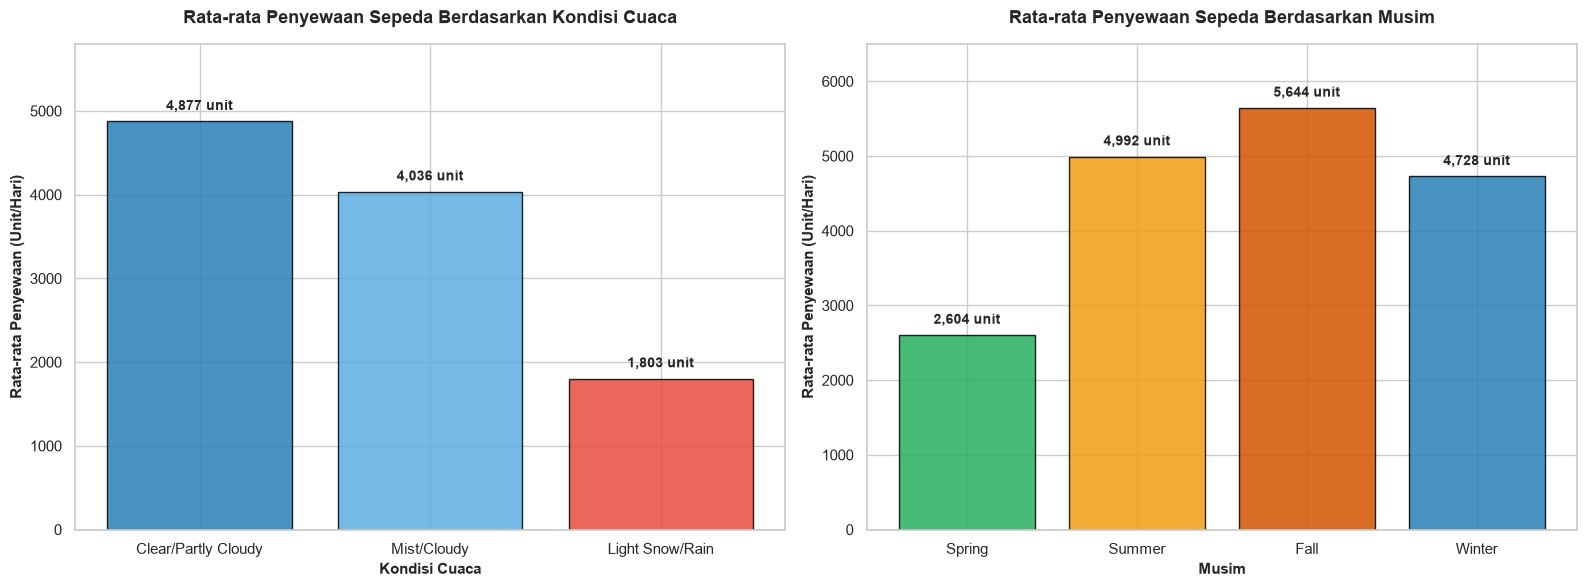

In [6]:
# Visualisasi Pertanyaan 1: Pengaruh Cuaca dan Musim terhadap Penyewaan Sepeda
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Kondisi Cuaca
weather_order = ['Clear/Partly Cloudy', 'Mist/Cloudy', 'Light Snow/Rain']
weather_data = day_df.groupby('weather_label')['cnt'].mean().reindex(weather_order).reset_index()

colors_weather = ['#2980b9', '#5dade2', '#e74c3c']
bars1 = axes[0].bar(weather_data['weather_label'], weather_data['cnt'], color=colors_weather, edgecolor='black', alpha=0.85)
axes[0].set_title('Rata-rata Penyewaan Sepeda Berdasarkan Kondisi Cuaca', fontsize=13, fontweight='bold', pad=15)
axes[0].set_xlabel('Kondisi Cuaca', fontsize=11, fontweight='semibold')
axes[0].set_ylabel('Rata-rata Penyewaan (Unit/Hari)', fontsize=11, fontweight='semibold')
axes[0].set_ylim(0, 5800)

for bar in bars1:
    h = bar.get_height()
    axes[0].annotate(f'{h:,.0f} unit',
                     xy=(bar.get_x() + bar.get_width() / 2, h),
                     xytext=(0, 6),
                     textcoords="offset points",
                     ha='center', va='bottom', fontsize=10, fontweight='bold')

# Subplot 2: Musim
season_order = ['Spring', 'Summer', 'Fall', 'Winter']
season_data = day_df.groupby('season_label')['cnt'].mean().reindex(season_order).reset_index()

colors_season = ['#27ae60', '#f39c12', '#d35400', '#2980b9']
bars2 = axes[1].bar(season_data['season_label'], season_data['cnt'], color=colors_season, edgecolor='black', alpha=0.85)
axes[1].set_title('Rata-rata Penyewaan Sepeda Berdasarkan Musim', fontsize=13, fontweight='bold', pad=15)
axes[1].set_xlabel('Musim', fontsize=11, fontweight='semibold')
axes[1].set_ylabel('Rata-rata Penyewaan (Unit/Hari)', fontsize=11, fontweight='semibold')
axes[1].set_ylim(0, 6500)

for bar in bars2:
    h = bar.get_height()
    axes[1].annotate(f'{h:,.0f} unit',
                     xy=(bar.get_x() + bar.get_width() / 2, h),
                     xytext=(0, 6),
                     textcoords="offset points",
                     ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

### Pertanyaan 2: Bagaimana pola fluktuasi penyewaan sepeda per jam pada hari kerja dibandingkan akhir pekan/libur, dan pada jam berapa terjadi jam sibuk (peak hours)?

findfont: Failed to find font weight semibold for Arial, now using 700.


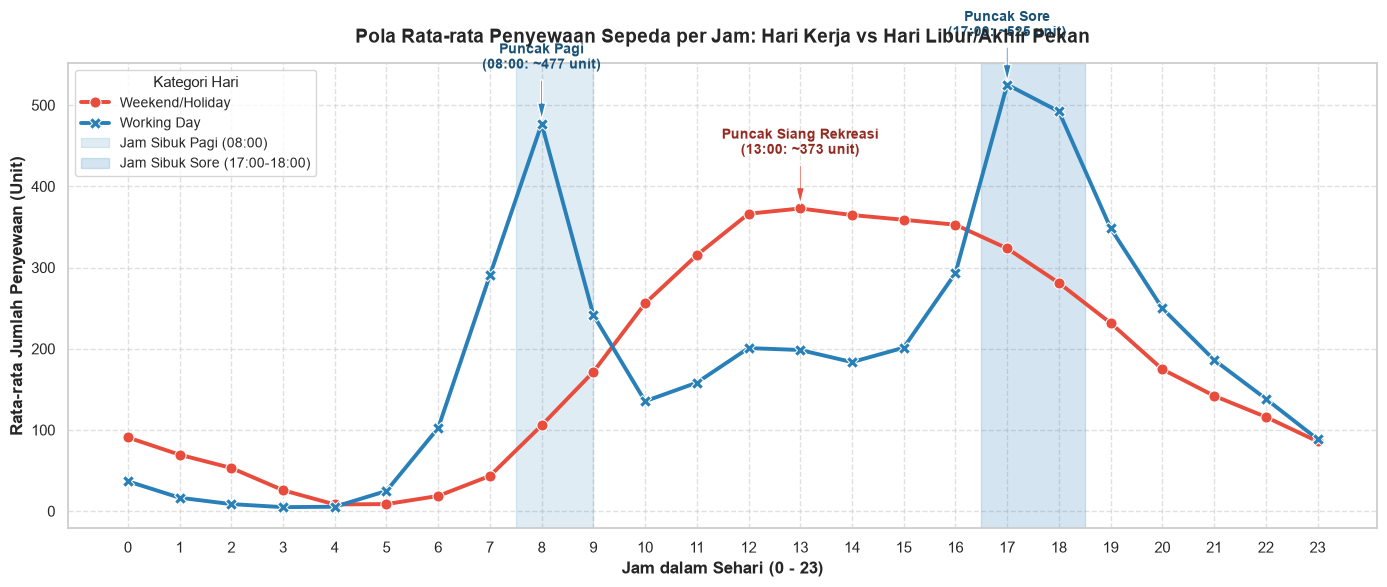

In [7]:
# Visualisasi Pertanyaan 2: Pola Jam Sibuk Penyewaan Sepeda (Hari Kerja vs Akhir Pekan)
hourly_avg = hour_df.groupby(['hr', 'workingday_label'])['cnt'].mean().reset_index()

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=hourly_avg,
    x='hr',
    y='cnt',
    hue='workingday_label',
    style='workingday_label',
    markers=True,
    dashes=False,
    palette=['#e74c3c', '#2980b9'],
    linewidth=2.8,
    markersize=8
)

# Area shading untuk jam sibuk hari kerja
plt.axvspan(7.5, 9.0, color='#2980b9', alpha=0.15, label='Jam Sibuk Pagi (08:00)')
plt.axvspan(16.5, 18.5, color='#2980b9', alpha=0.20, label='Jam Sibuk Sore (17:00-18:00)')

# Anotasi teks pada titik-titik puncak
plt.annotate('Puncak Pagi\n(08:00: ~477 unit)', xy=(8, 477), xytext=(8, 545),
             arrowprops=dict(facecolor='#2980b9', shrink=0.08, width=1.5, headwidth=6),
             ha='center', fontsize=10, fontweight='bold', color='#1a5276')

plt.annotate('Puncak Sore\n(17:00: ~525 unit)', xy=(17, 525), xytext=(17, 585),
             arrowprops=dict(facecolor='#2980b9', shrink=0.08, width=1.5, headwidth=6),
             ha='center', fontsize=10, fontweight='bold', color='#1a5276')

plt.annotate('Puncak Siang Rekreasi\n(13:00: ~373 unit)', xy=(13, 373), xytext=(13, 440),
             arrowprops=dict(facecolor='#e74c3c', shrink=0.08, width=1.5, headwidth=6),
             ha='center', fontsize=10, fontweight='bold', color='#922b21')

plt.title('Pola Rata-rata Penyewaan Sepeda per Jam: Hari Kerja vs Hari Libur/Akhir Pekan', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Jam dalam Sehari (0 - 23)', fontsize=12, fontweight='semibold')
plt.ylabel('Rata-rata Jumlah Penyewaan (Unit)', fontsize=12, fontweight='semibold')
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Kategori Hari', fontsize=10, title_fontsize=11, loc='upper left')

plt.tight_layout()
plt.show()

**Insight:**
- **Analisis Pertanyaan 1 (Pengaruh Cuaca & Musim):**
  - Cuaca cerah (*Clear/Partly Cloudy*) merupakan kondisi optimal bagi operasional dengan rata-rata **4.877 unit/hari**. Saat berkabut (*Mist/Cloudy*), jumlah sewa turun moderat ke **4.036 unit/hari**. Pada cuaca hujan/salju (*Light Snow/Rain*), penyewaan anjlok signifikan menjadi hanya **1.803 unit/hari** (penurunan 63%).
  - Dari sisi musim, musim gugur (*Fall*) menghasilkan jumlah penyewaan tertinggi (**5.644 unit/hari**), disusul musim panas (*Summer* - **4.992 unit/hari**) dan musim dingin (*Winter* - **4.728 unit/hari**). Musim semi (*Spring*) memiliki volume sewa terendah (**2.604 unit/hari**).
- **Analisis Pertanyaan 2 (Pola Jam Sibuk):**
  - Pada hari kerja, pola grafik berbentuk *bimodal* dengan dua lonjakan tajam: **pukul 08:00 (477 unit)** dan **pukul 17:00-18:00 (525 dan 492 unit)**. Hal ini menunjukkan ketergantungan tinggi pada perjalanan komuter harian.
  - Pada akhir pekan, kurva berbentuk lonceng santai (*unimodal*) dengan puncak penggunaan berada di siang hari (**pukul 12:00 - 15:00**, puncak di **pukul 13:00 sebesar 373 unit**), mencerminkan pola kegiatan rekreasi.

## Analisis Lanjutan (Opsional)

casual  registered         cnt         
                            mean        mean        mean      sum
time_category                                                    
Early Morning (00-05)   4.507717   20.400842   24.908559   106509
Evening Rush (16-19)   64.490741  313.139232  377.629973  1101169
Midday (10-15)         66.193866  163.998627  230.192493  1005711
Morning Rush (06-09)   16.955609  199.748451  216.704061   629742
Night (20-23)          25.485234  128.892514  154.377747   449548

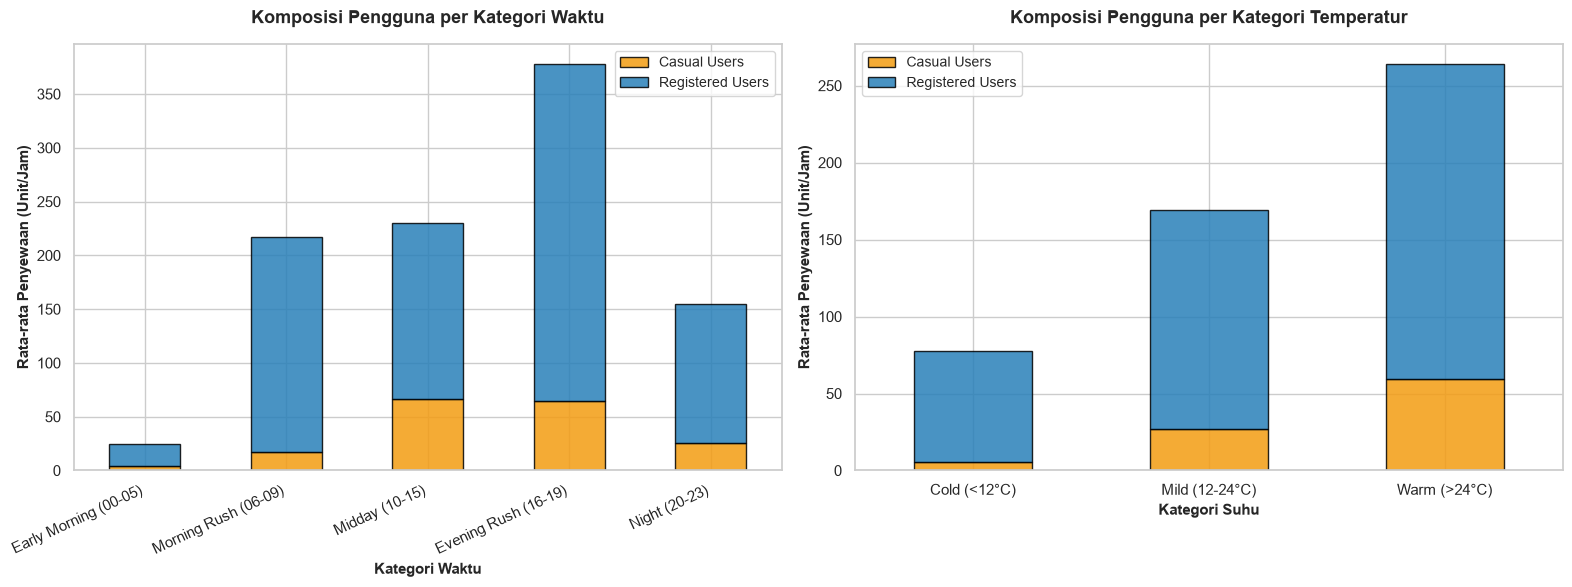

In [8]:
# Analisis Lanjutan: Time-of-Day Binning & User Type Segmentation

# 1. Fungsi pengelompokan waktu (Time-of-Day)
def categorize_time_of_day(hour):
    if 0 <= hour <= 5:
        return 'Early Morning (00-05)'
    elif 6 <= hour <= 9:
        return 'Morning Rush (06-09)'
    elif 10 <= hour <= 15:
        return 'Midday (10-15)'
    elif 16 <= hour <= 19:
        return 'Evening Rush (16-19)'
    else:
        return 'Night (20-23)'

# 2. Fungsi pengelompokan temperatur (Temperature Binning)
def categorize_temperature(temp_norm):
    temp_celsius = temp_norm * 41
    if temp_celsius < 12:
        return 'Cold (<12°C)'
    elif 12 <= temp_celsius <= 24:
        return 'Mild (12-24°C)'
    else:
        return 'Warm (>24°C)'

hour_df['time_category'] = hour_df['hr'].apply(categorize_time_of_day)
hour_df['temp_category'] = hour_df['temp'].apply(categorize_temperature)

# Ringkasan segmentasi waktu
time_summary = hour_df.groupby('time_category')[['casual', 'registered', 'cnt']].agg({
    'casual': 'mean',
    'registered': 'mean',
    'cnt': ['mean', 'sum']
})
display(time_summary)

# Visualisasi Komposisi Pengguna Kasual vs Terdaftar
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Segmentasi Waktu
time_order = ['Early Morning (00-05)', 'Morning Rush (06-09)', 'Midday (10-15)', 'Evening Rush (16-19)', 'Night (20-23)']
time_user_data = hour_df.groupby('time_category')[['casual', 'registered']].mean().reindex(time_order)

time_user_data.plot(
    kind='bar',
    stacked=True,
    color=['#f39c12', '#2980b9'],
    edgecolor='black',
    alpha=0.85,
    ax=axes[0]
)
axes[0].set_title('Komposisi Pengguna per Kategori Waktu', fontsize=13, fontweight='bold', pad=15)
axes[0].set_xlabel('Kategori Waktu', fontsize=11, fontweight='semibold')
axes[0].set_ylabel('Rata-rata Penyewaan (Unit/Jam)', fontsize=11, fontweight='semibold')
axes[0].set_xticklabels(time_order, rotation=25, ha='right')
axes[0].legend(['Casual Users', 'Registered Users'], fontsize=10)

# Subplot 2: Segmentasi Temperatur
temp_order = ['Cold (<12°C)', 'Mild (12-24°C)', 'Warm (>24°C)']
temp_user_data = hour_df.groupby('temp_category')[['casual', 'registered']].mean().reindex(temp_order)

temp_user_data.plot(
    kind='bar',
    stacked=True,
    color=['#f39c12', '#2980b9'],
    edgecolor='black',
    alpha=0.85,
    ax=axes[1]
)
axes[1].set_title('Komposisi Pengguna per Kategori Temperatur', fontsize=13, fontweight='bold', pad=15)
axes[1].set_xlabel('Kategori Suhu', fontsize=11, fontweight='semibold')
axes[1].set_ylabel('Rata-rata Penyewaan (Unit/Jam)', fontsize=11, fontweight='semibold')
axes[1].set_xticklabels(temp_order, rotation=0)
axes[1].legend(['Casual Users', 'Registered Users'], fontsize=10)

plt.tight_layout()
plt.show()

**Insight:**
- **Karakteristik Kategori Waktu:**
  - Periode *Evening Rush* (16:00 - 19:00) dan *Morning Rush* (06:00 - 09:00) memiliki intensitas sewa tertinggi per jam yang didominasi lebih dari 85% oleh pengguna terdaftar (*registered users*).
  - Periode *Midday* (10:00 - 15:00) memiliki porsi pengguna kasual (*casual users*) tertinggi, menandakan bahwa pengguna kasual lebih aktif saat siang hari.
  - Periode *Early Morning* (00:00 - 05:00) adalah periode dengan volume penggunaan paling minim (< 25 unit/jam), sehingga merupakan waktu terbaik untuk melakukan pemeliharaan armada dan rebalancing stasiun.
- **Karakteristik Kategori Temperatur:**
  - Kategori *Warm* (>24°C) mencatatkan tingkat penggunaan tertinggi, di mana pengguna kasual melonjak signifikan.
  - Pengguna kasual sangat sensitif terhadap suhu dingin (*Cold <12°C*), di mana aktivitas sewa kasual turun drastis, sedangkan pengguna terdaftar masih tetap aktif menyewa untuk mobilitas rutin.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:**
  1. **Pengaruh Kondisi Cuaca:** Cuaca berpengaruh sangat signifikan terhadap jumlah penyewaan sepeda. Cuaca cerah (*Clear/Partly Cloudy*) mendominasi dengan rata-rata tertinggi yaitu **4.877 unit/hari**, diikuti cuaca berkabut (*Mist/Cloudy*) sebesar **4.036 unit/hari**. Pada cuaca hujan atau salju ringan (*Light Snow/Rain*), penyewaan anjlok drastis ke **1.803 unit/hari** (turun 63,0%).
  2. **Pengaruh Musim:** Musim gugur (*Fall*) menjadi musim paling ramai penyewaan dengan rata-rata **5.644 unit/hari**, diikuti musim panas (*Summer* - **4.992 unit/hari**) dan musim dingin (*Winter* - **4.728 unit/hari**). Musim semi (*Spring*) memiliki tingkat utilisasi terendah (**2.604 unit/hari**).

- **Conclusion pertanyaan 2:**
  1. **Pola Jam Sibuk Hari Kerja:** Pada hari kerja (*Working Day*), pola penyewaan membentuk dua puncak tajam (*bimodal*), yaitu pada **pukul 08:00 (477 unit)** dan puncak utama sore hari pada **pukul 17:00 (525 unit) dan 18:00 (492 unit)**. Aktivitas ini sangat didominasi oleh pengguna terdaftar untuk keperluan mobilitas harian (bekerja/sekolah).
  2. **Pola Akhir Pekan / Hari Libur:** Pada akhir pekan dan hari libur (*Weekend/Holiday*), pola penyewaan membentuk kurva tunggal landai (*unimodal*) dengan puncak di tengah hari (**pukul 12:00 - 15:00**, titik tertinggi pada **pukul 13:00 sebesar 373 unit**). Pengguna kasual (*casual users*) berkontribusi paling besar pada periode ini untuk kebutuhan rekreasi dan santai.

**Rekomendasi Action Item:**

1. **Optimalisasi Manajemen Armada & Rebalancing Stasiun:**
   - Melakukan penataan ulang sepeda (*fleet rebalancing*) secara intensif sebelum pukul 07:30 di stasiun pemukiman/stasiun transportasi publik, dan sebelum pukul 16:30 di stasiun perkantoran/kampus pada hari kerja untuk mencegah dock kosong maupun dock penuh.
2. **Program Konversi Pengguna Kasual di Akhir Pekan:**
   - Menghadirkan paket penawaran khusus akhir pekan (*Weekend Leisure Pass*) atau diskon langganan berjangka untuk mengonversi tingginya volume pengguna kasual saat akhir pekan menjadi pengguna terdaftar (*registered members*).
3. **Penjadwalan Pemeliharaan Armada (Maintenance Window):**
   - Mengalokasikan aktivitas perawatan unit, inspeksi teknis, dan perbaikan docking pada periode *Early Morning* (pukul 00:00 - 05:00) atau saat hari-hari berstatus prakiraan cuaca buruk (*Light Snow/Rain*) ketika tingkat penyewaan sedang minim.
4. **Kampanye Promosi di Musim Semi (Spring Revamp):**
   - Merancang program promosi awal musim (*Early Spring Incentive*) untuk mendorong minat bersepeda lebih cepat setelah melewati musim dingin.